In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from scipy.stats import randint, uniform

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
np.random.seed(RANDOM_STATE)

n = 600

df = pd.DataFrame({
    "application_date": pd.date_range(
        start="2024-01-01",
        periods=n,
        freq="D"
    ),

    "income": np.random.randint(20000, 150000, n),

    "credit_score": np.random.randint(300, 850, n),

    "employment_type": np.random.choice(
        ["Salaried", "Self-employed", "Business"],
        n
    ),

    "education_level": np.random.choice(
        ["High School", "Graduate", "Postgraduate"],
        n
    ),

    "city": np.random.choice(
        ["Chennai", "Coimbatore", "Bangalore", "Erode"],
        n
    ),

    "loan_amount": np.random.randint(50000, 1000000, n)
})

# Generate classification target

default_probability = (
    0.45
    - (df["credit_score"] - 300) / 1000
    + (df["loan_amount"] / 1000000) * 0.20
    - (df["income"] / 150000) * 0.10
)

default_probability = np.clip(
    default_probability,
    0.05,
    0.80
)

df["loan_default"] = (
    np.random.random(n) < default_probability
).astype(int)

# Introduce missing values

for col in ["income", "credit_score"]:
    df.loc[
        df.sample(frac=0.05, random_state=RANDOM_STATE).index,
        col
    ] = np.nan

for col in ["employment_type", "education_level", "city"]:
    df.loc[
        df.sample(frac=0.05, random_state=RANDOM_STATE + 1).index,
        col
    ] = np.nan

print("Dataset created successfully!")

print("\nDataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTarget Distribution:")
print(df["loan_default"].value_counts())

Dataset created successfully!

Dataset Shape:
(600, 8)

First 5 Rows:


,application_date,income,credit_score,employment_type,education_level,city,loan_amount,loan_default
0,2024-01-01,141958.0,649.0,Self-employed,High School,Chennai,595909,0
1,2024-01-02,35795.0,346.0,Salaried,Graduate,Chennai,652272,1
2,2024-01-03,NaN,NaN,Self-employed,High School,Chennai,503008,0
3,2024-01-04,123694.0,669.0,Self-employed,Graduate,Bangalore,488469,1
4,2024-01-05,148106.0,405.0,Self-employed,High School,Bangalore,870483,1



Missing Values:
application_date     0
income              30
credit_score        30
employment_type     30
education_level     30
city                30
loan_amount          0
loan_default         0
dtype: int64

Target Distribution:
loan_default
0    452
1    148
Name: count, dtype: int64


In [3]:
df["application_month"] = (
    df["application_date"].dt.month
)

df["income_loan_ratio"] = (
    df["income"] / df["loan_amount"]
)

df["log_loan_amount"] = np.log1p(
    df["loan_amount"]
)

print("Feature engineering completed!")

display(df.head())

Feature engineering completed!


,application_date,income,credit_score,employment_type,education_level,city,loan_amount,loan_default,application_month,income_loan_ratio,log_loan_amount
0,2024-01-01,141958.0,649.0,Self-employed,High School,Chennai,595909,0,1,0.238221,13.297845
1,2024-01-02,35795.0,346.0,Salaried,Graduate,Chennai,652272,1,1,0.054877,13.388218
2,2024-01-03,NaN,NaN,Self-employed,High School,Chennai,503008,0,1,NaN,13.128363
3,2024-01-04,123694.0,669.0,Self-employed,Graduate,Bangalore,488469,1,1,0.253228,13.099033
4,2024-01-05,148106.0,405.0,Self-employed,High School,Bangalore,870483,1,1,0.170142,13.676805


In [4]:
df["application_month"] = (
    df["application_date"].dt.month
)

df["income_loan_ratio"] = (
    df["income"] / df["loan_amount"]
)

df["log_loan_amount"] = np.log1p(
    df["loan_amount"]
)

print("Feature engineering completed!")

display(df.head())

Feature engineering completed!


,application_date,income,credit_score,employment_type,education_level,city,loan_amount,loan_default,application_month,income_loan_ratio,log_loan_amount
0,2024-01-01,141958.0,649.0,Self-employed,High School,Chennai,595909,0,1,0.238221,13.297845
1,2024-01-02,35795.0,346.0,Salaried,Graduate,Chennai,652272,1,1,0.054877,13.388218
2,2024-01-03,NaN,NaN,Self-employed,High School,Chennai,503008,0,1,NaN,13.128363
3,2024-01-04,123694.0,669.0,Self-employed,Graduate,Bangalore,488469,1,1,0.253228,13.099033
4,2024-01-05,148106.0,405.0,Self-employed,High School,Bangalore,870483,1,1,0.170142,13.676805


In [5]:

X = df.drop(
    columns=["loan_default", "loan_amount", "application_date"]
)

y = df["loan_default"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (360, 8)
Validation: (120, 8)
Testing: (120, 8)


In [6]:
numeric_features = [
    "income",
    "credit_score",
    "application_month",
    "income_loan_ratio",
    "log_loan_amount"
]

categorical_features = [
    "employment_type",
    "city"
]

ordinal_features = [
    "education_level"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

ordinal_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        categories=[["High School", "Graduate", "Postgraduate"]]
    ))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
    ("ord", ordinal_pipeline, ordinal_features)
])

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [7]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    ),

    "XGBoost": xgb.XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=RANDOM_STATE
    )
}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "trained successfully!")

Logistic Regression trained successfully!
Random Forest trained successfully!
XGBoost trained successfully!


In [8]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, y_pred, zero_division=0
    )

    auc = roc_auc_score(
        y_val,
        model.predict_proba(X_val)[:, 1]
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC-AUC": auc
    })

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1 Score:", f1)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val, y_pred))

results_df = pd.DataFrame(results)

display(results_df)


Logistic Regression
Accuracy: 0.775
Precision: 0.5882352941176471
Recall: 0.3333333333333333
F1 Score: 0.425531914893617

Confusion Matrix:
[[83  7]
 [20 10]]

Random Forest
Accuracy: 0.75
Precision: 0.5
Recall: 0.3
F1 Score: 0.375

Confusion Matrix:
[[81  9]
 [21  9]]

XGBoost
Accuracy: 0.7
Precision: 0.375
Recall: 0.3
F1 Score: 0.3333333333333333

Confusion Matrix:
[[75 15]
 [21  9]]


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.775,0.588235,0.333333,0.425532,0.727407
1,Random Forest,0.750,0.500000,0.300000,0.375000,0.687593
2,XGBoost,0.700,0.375000,0.300000,0.333333,0.617407


In [9]:
print("""
WHY ACCURACY CAN BE MISLEADING:

Accuracy measures the percentage of total correct predictions.

When a dataset has imbalanced classes, a model may predict
the majority class most of the time and still achieve
high accuracy.

For example:

If 95% of customers do not default and 5% default,
a model predicting every customer as non-default
can achieve 95% accuracy.

However, it completely fails to identify default cases.

Therefore, Precision, Recall, F1 Score and ROC-AUC
are also important evaluation metrics.
""")


WHY ACCURACY CAN BE MISLEADING:

Accuracy measures the percentage of total correct predictions.

When a dataset has imbalanced classes, a model may predict
the majority class most of the time and still achieve
high accuracy.

For example:

If 95% of customers do not default and 5% default,
a model predicting every customer as non-default
can achieve 95% accuracy.

However, it completely fails to identify default cases.

Therefore, Precision, Recall, F1 Score and ROC-AUC
are also important evaluation metrics.



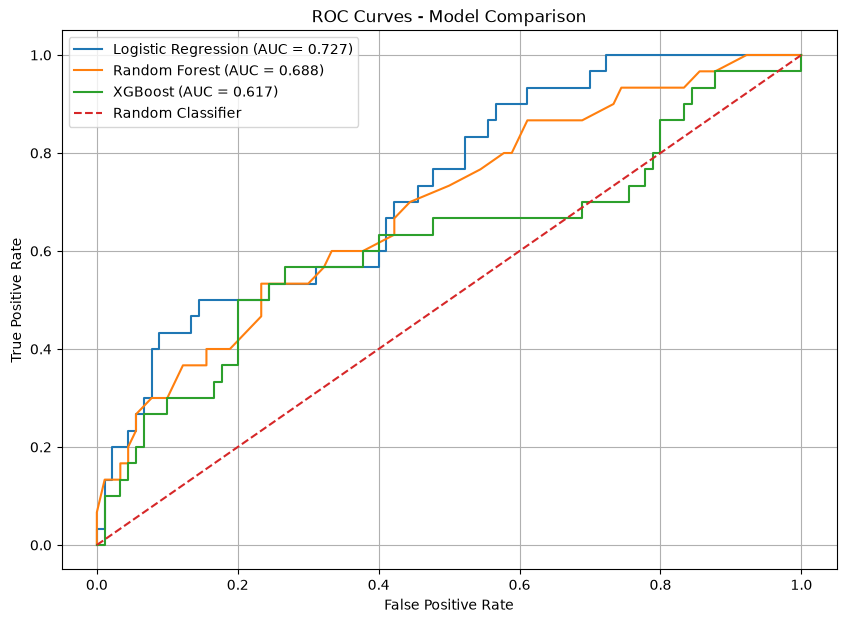

In [10]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_probability = model.predict_proba(X_val)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_val,
        y_probability
    )

    auc = roc_auc_score(
        y_val,
        y_probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curves - Model Comparison")

plt.legend()
plt.grid()

plt.show()

In [11]:
xgb_model = trained_models["XGBoost"]

y_probability = xgb_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_probability >= threshold
    ).astype(int)

    recall = recall_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    precision = precision_score(
        y_val,
        y_pred_threshold,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Recall": recall,
        "Precision": precision
    })

threshold_df = pd.DataFrame(threshold_results)

valid_thresholds = threshold_df[
    threshold_df["Recall"] >= 0.75
]

if len(valid_thresholds) > 0:

    best_threshold_row = valid_thresholds.sort_values(
        "Precision",
        ascending=False
    ).iloc[0]

    best_threshold = best_threshold_row["Threshold"]

    print("Selected Threshold:", best_threshold)

    print("Recall:", best_threshold_row["Recall"])

    print("Precision:", best_threshold_row["Precision"])

else:

    best_threshold = None

    print("No threshold achieved 75% recall.")

No threshold achieved 75% recall.


In [12]:
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        random_state=RANDOM_STATE
    ))
])

rf_parameters = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_split": [2, 5]
}

rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_parameters,
    cv=3,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("\nRandom Forest Best Parameters:")
print(rf_grid.best_params_)

print("\nRandom Forest Best CV ROC-AUC:")
print(rf_grid.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits

Random Forest Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}

Random Forest Best CV ROC-AUC:
0.6908512390121585


In [13]:
xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", xgb.XGBClassifier(
        eval_metric="logloss",
        random_state=RANDOM_STATE
    ))
])

xgb_parameters = {
    "classifier__n_estimators": randint(50, 250),

    "classifier__max_depth": randint(2, 8),

    "classifier__learning_rate": uniform(0.01, 0.20),

    "classifier__subsample": uniform(0.7, 0.3),

    "classifier__colsample_bytree": uniform(0.7, 0.3)
}

xgb_random = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameters,
    n_iter=15,
    cv=3,
    scoring="roc_auc",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

xgb_random.fit(X_train, y_train)

print("\nXGBoost Best Parameters:")
print(xgb_random.best_params_)

print("\nXGBoost Best CV ROC-AUC:")
print(xgb_random.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits

XGBoost Best Parameters:
{'classifier__colsample_bytree': np.float64(0.8834959481464842), 'classifier__learning_rate': np.float64(0.011413261043943482), 'classifier__max_depth': 2, 'classifier__n_estimators': 98, 'classifier__subsample': np.float64(0.8574323980775167)}

XGBoost Best CV ROC-AUC:
0.7141459774793107


In [14]:
tuned_models = {
    "Logistic Regression": trained_models["Logistic Regression"],
    "Random Forest": rf_grid.best_estimator_,
    "XGBoost": xgb_random.best_estimator_
}

tuned_results = []

for name, model in tuned_models.items():

    probabilities = model.predict_proba(X_val)[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    auc = roc_auc_score(y_val, probabilities)

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    tuned_results.append({
        "Model": name,
        "ROC-AUC": auc,
        "F1": f1
    })

tuned_results_df = pd.DataFrame(tuned_results)

display(tuned_results_df)

best_model_name = tuned_results_df.sort_values(
    ["ROC-AUC", "F1"],
    ascending=False
).iloc[0]["Model"]

best_model = tuned_models[best_model_name]

print("\nBest Model:", best_model_name)

,Model,ROC-AUC,F1
0,Logistic Regression,0.727407,0.425532
1,Random Forest,0.695556,0.311111
2,XGBoost,0.700556,0.000000



Best Model: Logistic Regression


In [15]:
X_reg = df.drop(
    columns=[
        "loan_amount",
        "loan_default",
        "application_date",
        "log_loan_amount"
    ]
)

y_reg = df["loan_amount"]

X_reg_train, X_reg_temp, y_reg_train, y_reg_temp = train_test_split(
    X_reg,
    y_reg,
    test_size=0.40,
    random_state=RANDOM_STATE
)

X_reg_val, X_reg_test, y_reg_val, y_reg_test = train_test_split(
    X_reg_temp,
    y_reg_temp,
    test_size=0.50,
    random_state=RANDOM_STATE
)

reg_numeric = [
    "income",
    "credit_score",
    "application_month",
    "income_loan_ratio"
]

reg_categorical = [
    "employment_type",
    "city"
]

reg_ordinal = ["education_level"]

reg_preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, reg_numeric),
    ("cat", categorical_pipeline, reg_categorical),
    ("ord", ordinal_pipeline, reg_ordinal)
])

regression_model = Pipeline([
    ("preprocessor", reg_preprocessor),

    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE
    ))
])

regression_model.fit(
    X_reg_train,
    y_reg_train
)

reg_predictions = regression_model.predict(
    X_reg_val
)

mean_predictions = np.full(
    len(y_reg_val),
    y_reg_train.mean()
)

# Regression model metrics

mae = mean_absolute_error(
    y_reg_val,
    reg_predictions
)

rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        reg_predictions
    )
)

r2 = r2_score(
    y_reg_val,
    reg_predictions
)

# Mean baseline metrics

baseline_mae = mean_absolute_error(
    y_reg_val,
    mean_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_reg_val,
        mean_predictions
    )
)

baseline_r2 = r2_score(
    y_reg_val,
    mean_predictions
)

print("REGRESSION MODEL")

print("MAE:", mae)
print("RMSE:", rmse)
print("R-Squared:", r2)

print("\nMEAN BASELINE")

print("MAE:", baseline_mae)
print("RMSE:", baseline_rmse)
print("R-Squared:", baseline_r2)

REGRESSION MODEL
MAE: 53774.45408333334
RMSE: 102654.43766975844
R-Squared: 0.8730796706680253

MEAN BASELINE
MAE: 253884.23935185184
RMSE: 291018.2133108757
R-Squared: -0.020037348844523573


In [16]:
print("=" * 50)
print("FINAL MODEL EVALUATION")
print("=" * 50)

print("Best Model:", best_model_name)

# Evaluate selected model on test data once

final_predictions = best_model.predict(X_test)

final_probabilities = best_model.predict_proba(X_test)[:, 1]

final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    final_predictions,
    zero_division=0
)

final_auc = roc_auc_score(
    y_test,
    final_probabilities
)

print("\nFinal Test Metrics")

print("Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1 Score:", final_f1)
print("ROC-AUC:", final_auc)

print("\nFinal Confusion Matrix")

print(confusion_matrix(
    y_test,
    final_predictions
))

print("\nClassification Report")

print(classification_report(
    y_test,
    final_predictions
))

FINAL MODEL EVALUATION
Best Model: Logistic Regression

Final Test Metrics
Accuracy: 0.7333333333333333
Precision: 0.3333333333333333
Recall: 0.10344827586206896
F1 Score: 0.15789473684210525
ROC-AUC: 0.6502463054187192

Final Confusion Matrix
[[85  6]
 [26  3]]

Classification Report
              precision    recall  f1-score   support

           0       0.77      0.93      0.84        91
           1       0.33      0.10      0.16        29

    accuracy                           0.73       120
   macro avg       0.55      0.52      0.50       120
weighted avg       0.66      0.73      0.68       120



In [17]:
print("=" * 60)

print("WEEK 2 ASSESSMENT - TASK 4 SUMMARY")

print("=" * 60)

print("\nBest Model:", best_model_name)

print("Final Test ROC-AUC:", round(final_auc, 4))

print("Final Test F1:", round(final_f1, 4))

print("\nRegression Results")

print("MAE:", round(mae, 2))

print("RMSE:", round(rmse, 2))

print("R2:", round(r2, 4))

print("\nMean Baseline")

print("MAE:", round(baseline_mae, 2))

print("RMSE:", round(baseline_rmse, 2))

print("R2:", round(baseline_r2, 4))

print("\nConcepts Covered:")

print("1. Classification Metrics")

print("2. Confusion Matrix")

print("3. ROC-AUC")

print("4. Decision Threshold")

print("5. GridSearchCV")

print("6. RandomizedSearchCV")

print("7. Regression Metrics")

print("8. Final Test Evaluation")

print("\nTASK 4 COMPLETED SUCCESSFULLY!")

WEEK 2 ASSESSMENT - TASK 4 SUMMARY

Best Model: Logistic Regression
Final Test ROC-AUC: 0.6502
Final Test F1: 0.1579

Regression Results
MAE: 53774.45
RMSE: 102654.44
R2: 0.8731

Mean Baseline
MAE: 253884.24
RMSE: 291018.21
R2: -0.02

Concepts Covered:
1. Classification Metrics
2. Confusion Matrix
3. ROC-AUC
4. Decision Threshold
5. GridSearchCV
6. RandomizedSearchCV
7. Regression Metrics
8. Final Test Evaluation

TASK 4 COMPLETED SUCCESSFULLY!
